Reflective exercise

One important note: You need all files including "FEEDBACK" in the name to run this notebook, which are included in this repository.

The exercises you gave us, were not entirely easy for me, but with the materials you provided and good old stack overflow they were doable and I do notice an improvement in my coding skills. I have coded here and there a bit beforehand, but lastly I ended up with too much vibe coding. My goal for this course was to get back to coding myself. Your encouragement very much helped with that. I still used ChatGPT Model 5.5 sometimes as a tutor, but more for guiding and explaining topics than providing code snippets. 
I didn't find my errors in the exercises exciting enough to make a notebook about them. For my former student job, I had often to clip netCDFs with a shapefile and calculate statistics of that area. So I missed a bit this kind of task. Hence I created something similar for you, focusing on raster clipping and visualizing instead of statistics though. I hope it meets your expectations and fulfills the requirements. It is important you inspect the plot carefully. Note that I reproduce the error I had after the last code box and then make a final reflection. Enjoy!


1. Import the necessary libraries. We will use rasterio, geopandas, the Transformer from pyproj, matplotlib and contextily.

In [1]:
import rasterio
import rasterio.mask
from rasterio.transform import array_bounds
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx
from pyproj import Transformer
import numpy as np


2. Load and georeference the png-image. Assign the image the following coordinates in the upper left corner: 46.54210° N, 6.56744° E and 46.51137° N, 6.59682° E for the lower right corner.

Careful, they are in EPSG:4326, you must transform them first. The coordinate reference system (CRS) should be EPSG:2056.

Then save it as a Geotiff.

In [2]:
#transforming coordinates
upper_left = 6.56744, 46.54210
lower_right = 6.59682, 46.51137
transformer = Transformer.from_crs("EPSG:4326", "EPSG:2056", always_xy=True)
upper_left_2056 = transformer.transform(*upper_left)
lower_right_2056 = transformer.transform(*lower_right)

#PNG would be readable with Image as well
with rasterio.open('FEEDBACK_img.png') as src:
    image = src.read()
    
    #georeference
    transform = rasterio.transform.from_bounds(
        upper_left_2056[0], lower_right_2056[1],
        lower_right_2056[0], upper_left_2056[1],
        width=src.width, height=src.height
    )

    #save geotiff
    with rasterio.open('FEEDBACK_img.tif', 'w', driver='GTiff', width=src.width, 
                       height=src.height, count=src.count, dtype=src.dtypes[0], 
                       crs='EPSG:2056', transform=transform) as dst:
        dst.write(image)

#warning can be ignored, it is only printed, 
# because it reads an ungeoreferenced png

c:\Users\redqu\OneDrive\Documents\Master_UNIL_ENVI\master_env\Lib\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


3. Load the shapefile using geopandas and make sure, that the CRS matches the GeoTIFF one by reprojecting with .to_crs().

In [3]:
shapefile_2056 = gpd.read_file("FEEDBACK.shp").to_crs(crs="EPSG:2056")

In [4]:
##aid-cell for me, to make corrections, can be ignored for the task itself

# fig, ax = plt.subplots(figsize=(8, 10))
# with rasterio.open("FEEDBACK_img.tif") as src:
#     rasterio.plot.show(src, ax=ax)
# shapefile_2056.boundary.plot(ax=ax)
# plt.show()

4. Clip the Geotiff to the Shapefile. Use rasterio.mask.mask() for that. Change the arguments "crop=True" to reduce the raster extent to the bounding box of the polygon and "filled=False" to preserve the mask for pixels outside the polygon.

In [5]:
with rasterio.open("FEEDBACK_img.tif") as src:
    clipped_image, clipped_transform = rasterio.mask.mask(src, shapefile_2056.geometry, crop=True, filled=False)

In [ ]:
##aid-cell for me, to make corrections, can be ignored for the task itself

# print(type(clipped_image))
# print(clipped_image.mask.all())
# print(clipped_image.mask.any())

# with rasterio.open("FEEDBACK_img.tif") as src:
#     print("Bands:", src.count)


5. Plot the clipped and georeferenced raster with a satellite image as a basemap. You can choose e.g. the 'Esri.WorldImagery' from contextily. Make sure that the areas outside the polygon remain transparent, so the basemap is visible.

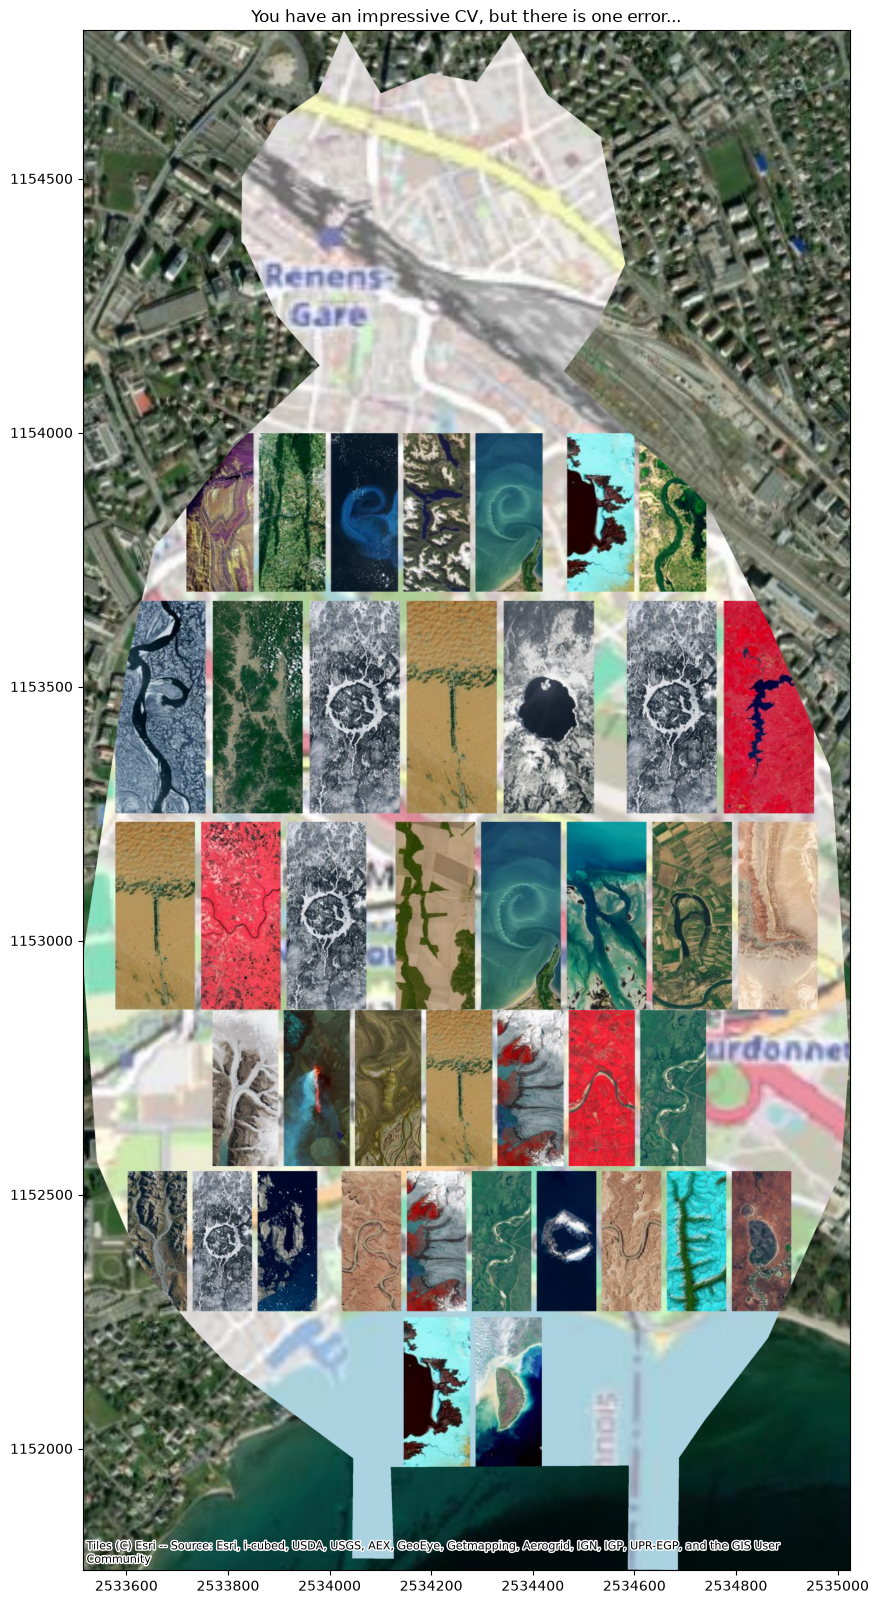

In [ ]:
# note: you need an internet-connection to load the basemap.

#only rgb bands
rgb = clipped_image[:3].filled(0).transpose(1, 2, 0)

# preserving original transparency and clipping mask
alpha = clipped_image[3].filled(0)

#combining rgb and alpha
rgba = np.dstack((rgb, alpha))

# get correct extent
left, bottom, right, top = array_bounds(
    clipped_image.shape[1],
    clipped_image.shape[2],
    clipped_transform
)
fig, ax = plt.subplots(figsize=(16, 20))
ax.imshow(
    rgba,
    extent=(left, right, bottom, top),
    origin="upper",
    zorder=2
)
cx.add_basemap(
    ax,
    crs="EPSG:2056",
    source=cx.providers.Esri.WorldImagery,
    zorder=0
)

plt.title("You have an impressive CV, but there is one error...")
ax.ticklabel_format(style="plain", useOffset=False)
plt.show()

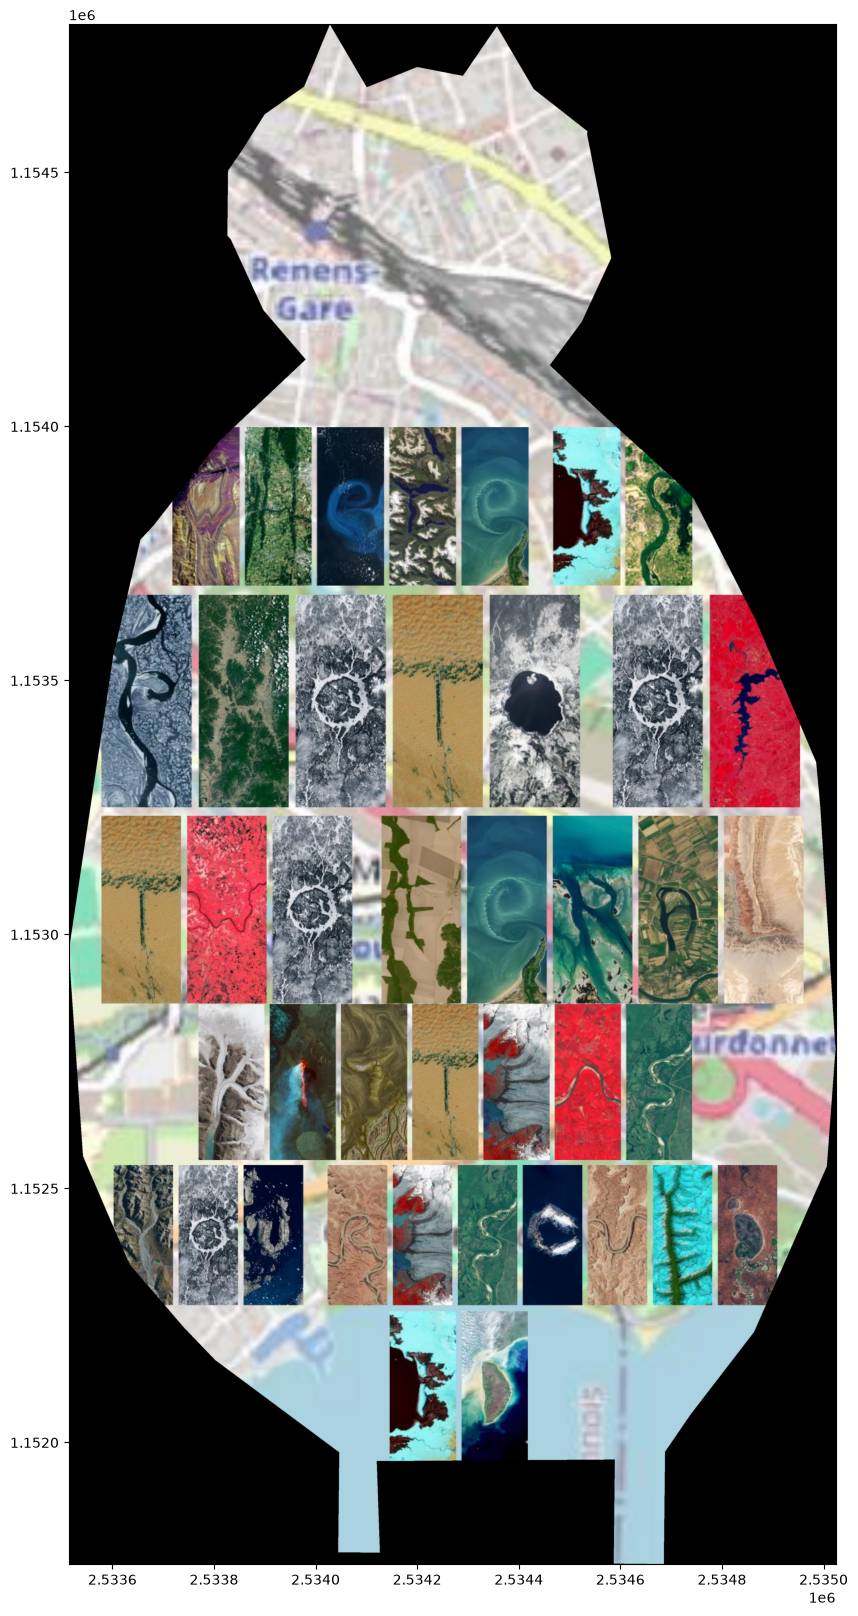

In [ ]:
# reproducing my error – masked pixels are not transparent:
# the clipping works geometrically, but the pixels outside 
# the intersecting area are not displayed transparent

import rasterio.plot

with rasterio.open("FEEDBACK_img.tif") as src:
    clipped_image, clipped_transform = rasterio.mask.mask(
        src, shapefile_2056.geometry,
        crop=True,
        filled=True
    )

fig, ax = plt.subplots(figsize=(16, 20))
# cx.add_basemap(
#     ax, 
#     crs="EPSG:2056", 
#     source=cx.providers.Esri.WorldImagery,
#     zorder=0
# )
rasterio.plot.show(clipped_image, transform=clipped_transform, ax=ax, zorder=2)

plt.show()

Reflection:

I had difficulties plotting the clipped image on the basemap. The problem was, that I initially forgot, that the png had a fourth band. It already contained the transparency information, so I kept its original values and set the masked pixels outside the polygonshape to zero to make them transparent. Finally the basemap was visible underneath. I found that through a python-tutorial, stackoverflow and a hint on what I should print from ChatGPT in order to find the solution

The other problem is the georeferencing. You might realize, that image does not align perfectly. Then I realized, that with the bounding box I must have stretched the image slightly. There are different ways, which could preserve the original proportions of the image, like affine or from_origin() with equal pixel sizes. But of course, the coordinates are probably not precise enough either.

And of course, in total there could have been more error handling as fallbacks, but as i know the data here, I ignored that.